In [ ]:
from google.colab import drive
drive.mount('/content/drive')

COU07506 – Digital Signal Processing

Week 1 Lab: Your First Notebook

In [ ]:
kimport numpy as np

import matplotlib.pyplot as plt

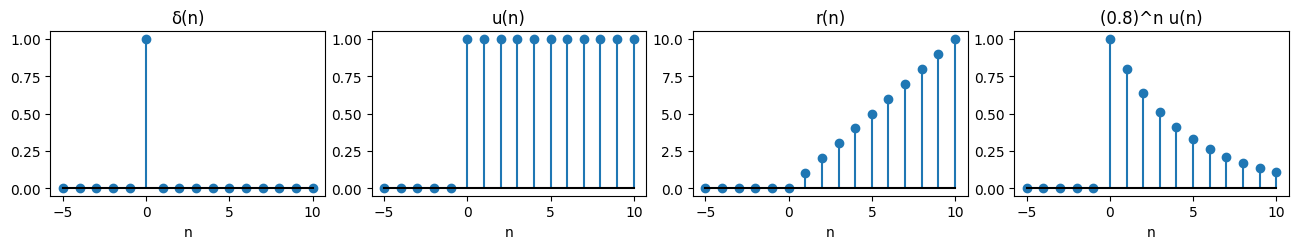

In [ ]:
no my fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

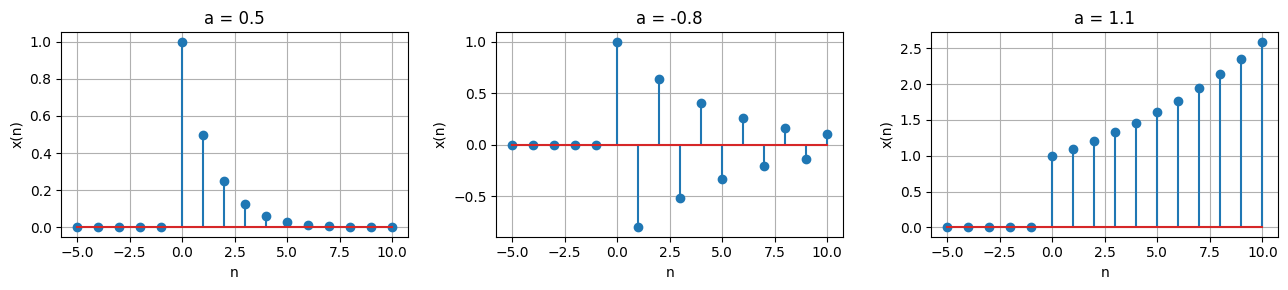

In [ ]:

n = np.arange(-5, 11)

a1 = 0.5
a2 = -0.8
a3 = 1.1

u = (n >= 0).astype(float)

x1 = (a1**n) * u
x2 = (a2**n) * u
x3 = (a3**n) * u

fig, axes = plt.subplots(1, 3, figsize=(13, 3))

axes[0].stem(n, x1)
axes[0].set_title("a = 0.5")

axes[1].stem(n, x2)
axes[1].set_title("a = -0.8")

axes[2].stem(n, x3)
axes[2].set_title("a = 1.1")

for ax in axes:
    ax.set_xlabel("n")
    ax.set_ylabel("x(n)")
    ax.grid()

plt.tight_layout()
plt.show()


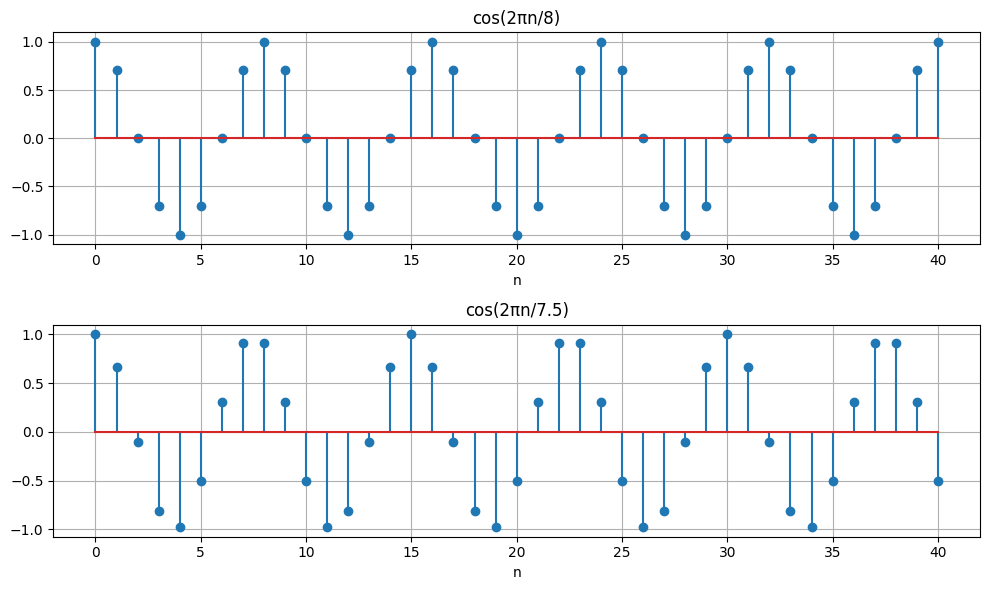

In [ ]:

n = np.arange(0, 41)

x1 = np.cos(2*np.pi*n/8)
x2 = np.cos(2*np.pi*n/7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n, x1)
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("n")
axes[0].grid()

axes[1].stem(n, x2)
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("n")
axes[1].grid()

plt.tight_layout()
plt.show()


Task 1.2 – Question 2

Question: Which one repeats exactly? Explain why.

Answer:

The signal cos(2πn/8) repeats exactly because its period is 8 samples, which is an integer.


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving My voice.m4a to My voice.m4a


ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

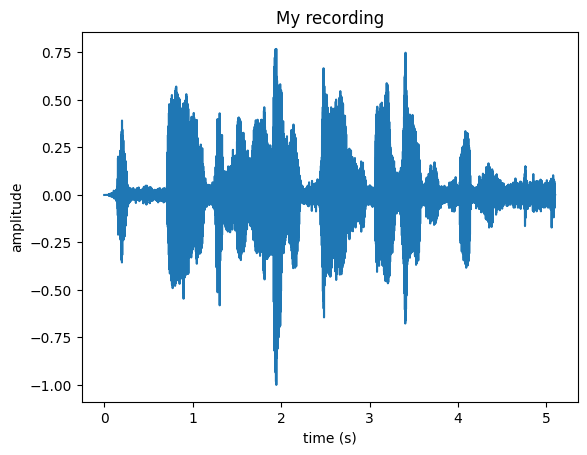

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio

# Pata jina la file ulilolipakia (mfano .m4a)
m4a_files = [f for f in os.listdir(".") if f.lower().endswith(".m4a")]
if len(m4a_files) > 0:
    src_file = m4a_files[0]
    wav_file = "my_voice.wav"
    # Badili .m4a kwenda .wav kwa kutumia ffmpeg
    !ffmpeg -y -i "$src_file" "$wav_file"
    fs, x = wavfile.read(wav_file)
    if x.ndim > 1:
        x = x.mean(axis=1)          # stereo -> mono
    x = x / np.max(np.abs(x))       # normalise to [-1, 1]
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2 * np.pi * 440 * t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()

Audio(x, rate=fs)

In [ ]:

# Trim audio to exactly 5 seconds

x_trim = x[:int(5 * fs)]

# Save the trimmed audio as WAV
from scipy.io import wavfile

wavfile.write("my_voice_5s.wav", fs, x_trim.astype(np.float32))

# Check duration
print("Sampling rate:", fs, "Hz")
print("New duration:", len(x_trim)/fs, "seconds")
print("Samples:", len(x_trim))


Sampling rate: 48000 Hz
New duration: 5.0 seconds
Samples: 240000


ANALYSIS QUESTIONS

Question 1: What is the sampling rate of your phone’s recording? How many numbers are needed to store one minute of it in mono?

Answer:

The sampling rate of my phone recording is 48,000 Hz.

Number of samples needed for one minute:

48,000 × 60 = 2,880,000 samples.

Therefore, 2,880,000 numbers are needed to store one minute of mono audio.

Question 2: Why is a stem plot more appropriate than a continuous line for x(n)?

Answer:

A stem plot is more appropriate because a discrete-time signal exists only at specific sample points. It clearly shows the individual samples.

Question 3: For a = 1.1 the exponential grows. Which property of a system would such a signal violate if it were an impulse response?

Answer:

It would violate the BIBO stability property because the impulse response grows without bound and is not absolutely summable.

In [1]:

from google.colab import drive, files

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
